# Prueba Intertrimestral

**Nombre:**  Lorena
**Apellidos:**  Lam Diez

**Tiempo de la prueba:** 2 horas  
**Asignatura:** Desarrollo de Aplicaciones para la Visualización de Datos  
**Fecha:** 19 de octubre de 2027  

## Instrucciones

- Escribe **código limpio y autoexplicativo**.  
- Se pueden utilizar **los materiales de clase**.  
- Se puede utilizar **internet** para búsqueda de dudas y documentación.  
- **No se puede utilizar ningún tipo de LLM** (ChatGPT, Copilot, Gemini, etc.).  
- **No se puede utilizar mensajería instantánea**.  
- Al finalizar, **sube tu notebook a GitHub** y envía el enlace del fichero según las instrucciones del profesor.

**[Subé el enlace aquí](https://forms.cloud.microsoft/e/vSwHis0f1B)**

## Dataset “City Micromobility Hourly”

El fichero `city_micromobility_hourly.csv` contiene **alquileres horarios** de bicicletas y patinetes compartidos en una ciudad (ene 2025 – dic 2026): meteorología, tipo de día, usuarios ocasionales/abonados, duración media, ingresos y una etiqueta de alta demanda.

Hay un `.txt` con la descripción de las variables en la misma carpeta.


## Inicialización de librerías


In [84]:
from __future__ import annotations

from datetime import date
from pathlib import Path

import numpy as np
import pandas as pd
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from itertools import combinations
from sklearn.metrics import mean_squared_error

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay


from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Ejercicio 1 — Programación (2 puntos)

a) (0.6 pts) Crea una función `rental_fee(duration_min, bike_type, is_member)` que calcule la tarifa de un viaje en euros, redondeada a **dos decimales**, con estas reglas:

- Tarifa base: **1.00 €** si `bike_type == "classic"`, **1.50 €** si `bike_type == "electric"`.
- Coste por minuto: **0.05 €/min** (classic) o **0.08 €/min** (electric).
- Si `is_member` es `True`, aplica un **20 % de descuento** sobre el total.
- Si `bike_type` no es `"classic"` ni `"electric"`, lanza `ValueError`.

Ejemplo orientativo: `rental_fee(20, "classic", False)` → `2.00`.


In [22]:
def rental_fee(duration_min: float, bike_type: str, is_member: bool) -> float:
    # Gestiono el error de tipo
    if bike_type not in ["classic", "electric"]:    #solo deberia ser de estos dos tipos
        raise ValueError("Tipo de bicicleta tiene que ser classic o electric")

    # Tarifa base y coste por minuto
    if bike_type == "classic":
        base_fee = 1.00
        minute_rate = 0.05
    else:  # si es electrica (pongo else porque ya hemos gestionado que solo pueda ser de esos dos tipos en el ValueError)
        base_fee = 1.50
        minute_rate = 0.08
    # total
    total_cost = base_fee + (minute_rate * duration_min)

    # decsuento
    if is_member:
        total_cost *= 0.80

    return round(total_cost, 2)

In [27]:
resultado = rental_fee(20, "classic", False)
print(f"Resultado: {resultado}")

Resultado: 2.0


b) (0.6 pts) Crea una función `demand_label(total_rentals, threshold)` que devuelva `"Alta"` si `total_rentals >= threshold`, `"Media"` si está entre `threshold/2` (incluido) y `threshold` (excluido), y `"Baja"` en caso contrario.


In [4]:
def demand_label(total_rentals: int, threshold: float) -> str:
    if total_rentals >= threshold:
        return "Alta"
    elif total_rentals >= (threshold / 2):
        return "Media"
    else:
        return "Baja"

In [28]:
resultado2 = demand_label(10,3.0)
print(f"Resultado: {resultado2}")

Resultado: Alta


c) (0.6 pts) Genera un DataFrame llamado `tripsDemo` con **al menos 10 filas** y columnas:

- `duration_min` (float)
- `bike_type` (`"classic"` o `"electric"`)
- `is_member` (bool)
- `fee` (calculada con `rental_fee`)
- `total_rentals` (int, inventado)
- `demand` (calculada con `demand_label`, usando por ejemplo `threshold=40`)

Muestra el DataFrame completo.


In [51]:

# Generación para 10 viajes
np.random.seed(42)
data_demo = {
    "duration_min": np.round(np.random.uniform(5.0, 45.0, 10), 1),
    "bike_type": np.random.choice(["classic", "electric"], 10),
    "is_member": np.random.choice([True, False], 10),
    "total_rentals": np.random.randint(5, 80, 10)
}

tripsDemo = pd.DataFrame(data_demo)

# fee
tripsDemo["fee"] = tripsDemo.apply(
    lambda r: rental_fee(r["duration_min"], r["bike_type"], r["is_member"]),
    axis=1
)

# demand label
tripsDemo["demand"] = tripsDemo["total_rentals"].apply(
    lambda x: demand_label(x, threshold=40)
)

tripsDemo

,duration_min,bike_type,is_member,total_rentals,fee,demand
0,20.0,electric,True,63,2.48,Alta
1,43.0,classic,True,46,2.52,Alta
2,34.3,electric,False,64,4.24,Alta
3,28.9,electric,False,19,3.81,Baja
4,11.2,electric,False,66,2.40,Alta
5,11.2,electric,True,66,1.92,Alta
6,7.3,electric,False,51,2.08,Alta
7,39.6,electric,True,66,3.73,Alta
8,29.0,electric,True,55,3.06,Alta
9,33.3,electric,True,59,3.33,Alta


d) (0.2 pts) Integra ambas funciones en una clase `MicromobilityTools` que, a partir de listas/arrays de `duration_min`, `bike_type` e `is_member`, calcule las tarifas y (opcionalmente) etiquete demanda a partir de una lista de `total_rentals` y un `threshold`.


In [32]:
class MicromobilityTools:
    @staticmethod
    def calculate_fees(durations: list[float] | np.ndarray, bike_types: list[str] | np.ndarray, members: list[bool] | np.ndarray) -> list[float]:
        fees = []
        for d, b, m in zip(durations, bike_types, members):
            fees.append(rental_fee(d, b, m))
        return fees

    @staticmethod
    def label_demands(rentals: list[int] | np.ndarray, threshold: float) -> list[str]:
        labels = []
        for r in rentals:
            labels.append(demand_label(r, threshold))
        return labels

In [40]:
# Prueba MicromobilityTools
duraciones = [15.0, 30.0, 45.0]
tipos_bicicleta = ["classic", "electric", "classic"]
miembros = [True, False, True]

# tarifas
tarifas = MicromobilityTools.calculate_fees(duraciones, tipos_bicicleta, miembros)
print("Tarifas:", tarifas)

# etiquetado
alquileres = [15, 30, 50]
etiquetas_demanda = MicromobilityTools.label_demands(alquileres, threshold=40)
print("Etiquetas:", etiquetas_demanda)

Tarifas: [1.4, 3.9, 2.6]
Etiquetas: ['Baja', 'Media', 'Alta']


## Ejercicio 2 — Exploración y visualización (3 puntos)

a) (0.75 pts) Carga `city_micromobility_hourly.csv` en un DataFrame `mobilityData`. Muestra las 5 primeras filas y el número de filas y columnas.


In [39]:
file_path = "/content/drive/MyDrive/Colab Notebooks/Análisis estratégico y visualización de datos/inter/city_micromobility_hourly.csv"
mobilityData = pd.read_csv(file_path)

print(f"{mobilityData.shape[0]} filas, {mobilityData.shape[1]} columnas.\n")

mobilityData.head()

17520 filas, 23 columnas.



,datetime,year,month,day,hour,weekday,season,is_holiday,is_weekend,is_workingday,...,wind_kmh,precip_mm,casual_users,member_users,total_rentals,avg_trip_min,avg_distance_km,electric_share,revenue_eur,high_demand
0,2025-01-01 00:00:00,2025,1,1,0,2,Winter,1,0,0,...,9.7,0.0,2,8,10,23.3,4.94,0.391,10.83,0
1,2025-01-01 01:00:00,2025,1,1,1,2,Winter,1,0,0,...,2.8,0.0,1,5,6,17.3,3.92,0.327,5.35,0
2,2025-01-01 02:00:00,2025,1,1,2,2,Winter,1,0,0,...,9.0,0.0,1,4,5,17.3,4.24,0.405,4.77,0
3,2025-01-01 03:00:00,2025,1,1,3,2,Winter,1,0,0,...,5.4,0.0,2,10,12,17.3,3.98,0.408,10.88,0
4,2025-01-01 04:00:00,2025,1,1,4,2,Winter,1,0,0,...,2.4,0.0,1,4,5,21.6,5.90,0.336,5.16,0


b) (0.75 pts) Crea una función `describeData(dataFrame)` que, para cada columna, devuelva: tipo de dato, número de nulos y porcentaje de nulos.


In [43]:
def describeData(dataFrame: pd.DataFrame) -> pd.DataFrame:
    desc_df = pd.DataFrame({
        "Tipo": dataFrame.dtypes,
        "Nulos": dataFrame.isnull().sum(),
        "Porcentaje nuls": (dataFrame.isnull().sum() / len(dataFrame)) * 100
    })
    return desc_df

In [44]:
describeData(mobilityData)


,Tipo,Nulos,Porcentaje nuls
datetime,object,0,0.000000
year,int64,0,0.000000
month,int64,0,0.000000
day,int64,0,0.000000
hour,int64,0,0.000000
weekday,int64,0,0.000000
season,object,0,0.000000
is_holiday,int64,0,0.000000
is_weekend,int64,0,0.000000
is_workingday,int64,0,0.000000


# c) Analizar los datos nulos usando nuestra función describeData


In [49]:

columns_with_nulls = analysis_df[analysis_df["Nulos"] > 0]
if len(columns_with_nulls) > 0:
    print("\nColumnas con valores nulos ")
    display(columns_with_nulls)
else:
    print("\nNo hay nulos")



Columnas con valores nulos 


,Tipo,Nulos,Porcentaje nuls
humidity,float64,224,1.278539
wind_kmh,float64,142,0.810502
avg_trip_min,float64,255,1.455479
electric_share,float64,182,1.038813


d) (0.75 pts) Elabora **dos** visualizaciones:

1. Un gráfico de correlación entre variables numéricas relevantes (por ejemplo `temp_c`, `humidity`, `wind_kmh`, `precip_mm`, `casual_users`, `member_users`, `total_rentals`, `revenue_eur`).
2. Un gráfico que muestre la demanda media (`total_rentals`) por `hour` (y, si quieres, separando fin de semana / laborable).

Comenta 2–3 hallazgos (correlaciones, horas punta, efecto del clima, etc.).


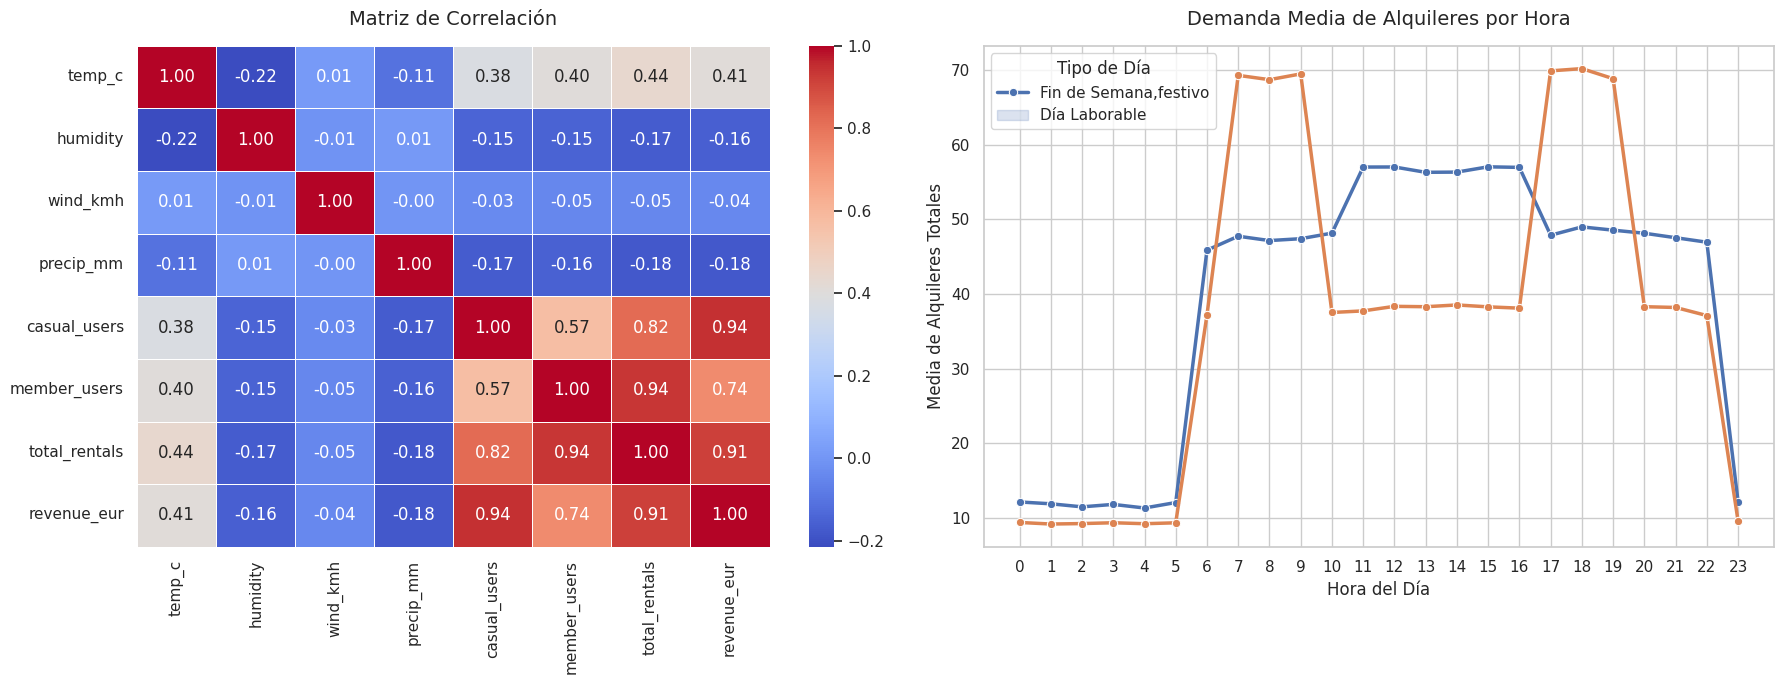

In [94]:

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# CORRELACIOON
corr_vars = ["temp_c", "humidity", "wind_kmh", "precip_mm", "casual_users", "member_users", "total_rentals", "revenue_eur"]
corr_matrix = mobilityData[corr_vars].corr()

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    ax=axes[0]
)
axes[0].set_title("Matriz de Correlación", fontsize=14, pad=15)

# DEMANDA POR HORA
hourly_demand = mobilityData.groupby(["hour", "is_workingday"])["total_rentals"].mean().reset_index()

sns.lineplot(
    data=hourly_demand,
    x="hour",
    y="total_rentals",
    hue="is_workingday",
    marker="o",
    linewidth=2.5,
    ax=axes[1]
)
axes[1].set_title("Demanda Media de Alquileres por Hora", fontsize=14, pad=15)
axes[1].set_xlabel("Hora del Día", fontsize=12)
axes[1].set_ylabel("Media de Alquileres Totales", fontsize=12)
axes[1].set_xticks(range(0, 24))
axes[1].legend(title="Tipo de Día", labels=["Fin de Semana,festivo", "Día Laborable"])

plt.tight_layout()
plt.show()


1) La temperatura ,temp_c, presenta una correlación fuerte y positiva con el total de alquileres, total_rentals, y los revenue_eur
   Los revenue_eur tienen una correlación casi perfecta con el total de volumen de alquileres, total_rentals.

2) Además la humidity podemos ver que tiene una correlación negativa con los alquileres, es decir que si hay humedad (probablemente es un dia de lluvia o mal tiempo) se reducen los alquileres de bicis ya que la gente prefiere no mojarse
   También vemos que aquellos member_users son los que tienen mayor num total de alquileres,  en comparación con los casual_users

3) En los dias laborables se ven mas picos relativos a la demanda en las horas puntas cuando la gente esta entrando (6,7,8 de la mañana) o saliendo de trabajar (5,6,7 de la tarde)
  Por otra parte en dias no laborables, festivos, la demanda cambia bastante, alcanzando sus maximos a las horas centrales del dia, que cuadra mas con un uso de ocio de 11 de la mañana a 4 de la tarde.

## Ejercicio 3 — Regresión (2 puntos)

Queremos predecir `total_rentals`.

a) (0.25 pts) Define `targetVar = "total_rentals"` y selecciona **3–5** variables predictoras numéricas razonables (p. ej. `hour`, `temp_c`, `humidity`, `wind_kmh`, `precip_mm`, `is_workingday`, `is_weekend`). Construye `X` e `y`, tratando nulos de forma simple (p. ej. eliminar filas o imputar la mediana).


In [60]:
targetVar = "total_rentals"
predictors = ["hour", "temp_c", "humidity", "wind_kmh", "is_workingday", "is_weekend"]

data_reg = mobilityData[predictors + [targetVar]].copy()

# elijo imputar mediana
for col in predictors:
    if data_reg[col].isnull().any():
        median_val = data_reg[col].median()
        data_reg[col] = data_reg[col].fillna(median_val)

X = data_reg[predictors]
y = data_reg[targetVar]

print(f"X: {X.shape}, Y: {y.shape}")

X: (17520, 6), Y: (17520,)


b) (0.25 pts) Divide en entrenamiento (70 %) y prueba (30 %) con `random_state=42`.


In [64]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42
)

print(f"Conjunto original (X_new): {X.shape[0]} registros.")
print("\nDimensiones de los conjuntos:")
print(f"X_train (70%): {X_train.shape}")
print(f"X_test (30%): {X_test.shape}")
print(f"y_train (70%): {y_train.shape}")
print(f"y_test (30%): {y_test.shape}")


Conjunto original (X_new): 17520 registros.

Dimensiones de los conjuntos:
X_train (70%): (12264, 6)
X_test (30%): (5256, 6)
y_train (70%): (12264,)
y_test (30%): (5256,)


c) (0.75 pts) Entrena un `LinearRegression`, calcula **R²** y **MSE** en el conjunto de prueba y comenta el resultado en 1–2 líneas.


In [80]:
lm = LinearRegression()

lm.fit(X_train, y_train)

y_pred = lm.predict(X_test)

# Calcular el R² (Coeficiente de Determinación)
r2 = r2_score(y_test, y_pred)

# Calcular el MSE (Mean Squared Error)
mse = mean_squared_error(y_test, y_pred)

print("--- Evaluación del Modelo de Regresión Lineal ---")
print(f"R² (Coeficiente de Determinación): {r2:.4f}")
print(f"MSE (Error Cuadrático Medio): {mse:.4f}")

--- Evaluación del Modelo de Regresión Lineal ---
R² (Coeficiente de Determinación): 0.3061
MSE (Error Cuadrático Medio): 417.4094


d) (0.75 pts) Entrena un `RandomForestRegressor` (mismo split) y compara R² y MSE con la regresión lineal. ¿Cuál funciona mejor y por qué crees que es así?


In [77]:
# d) Entrenar RandomForestRegressor y comparar resultados con la Regresión Lineal
from sklearn.ensemble import RandomForestRegressor

# Inicializar y entrenar el modelo de Random Forest
rf_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)

# Realizar predicciones sobre el conjunto de prueba
y_pred_rf = rf_model.predict(X_test)

# Calcular el R²
r2_rf = r2_score(y_test, y_pred_rf)

# Calcular el MSE
mse_rf = mean_squared_error(y_test, y_pred_rf)

print(f"--- Comparación de Rendimiento ---")
print(f"Regresión Lineal -> R²: {r2_lr:.4f} | MSE: {mse_lr:.2f}")
print(f"Random Forest    -> R²: {r2_rf:.4f} | MSE: {mse_rf:.2f}\n")


print("""
El modelo de RandomForestRegressor funciona  mejor que la regresión lineal ya que podemos ver que ha obtenido un R² mucho mas superior y un MSE significativamente menor.

Esto puede ocurrir porque los patrones de demanda son no lineales y  pueden depender altamente de interacciones complejas entre las variables que tenemos en el modelo. Por ejemplo, el impacto de la hora pico junto con si es un día laborable o fin de semana. Ya que por otro lado, la regresión lineal intenta ajustar una línea recta rígida  (es decir la relación lineal), Random Forest puede realizar múltiples árboles de decisión para reflejar esas relaciones de forma mas flexible.
""")

--- Comparación de Rendimiento ---
Regresión Lineal -> R²: 0.3061 | MSE: 417.41
Random Forest    -> R²: 0.8475 | MSE: 91.73


El modelo de RandomForestRegressor funciona  mejor que la regresión lineal ya que podemos ver que ha obtenido un R² mucho mas superior y un MSE significativamente menor.

Esto puede ocurrir porque los patrones de demanda son no lineales y  pueden depender altamente de interacciones complejas entre las variables que tenemos en el modelo. Por ejemplo, el impacto de la hora pico junto con si es un día laborable o fin de semana. Ya que por otro lado, la regresión lineal intenta ajustar una línea recta rígida) es decir la relación lineal), Random Forest puede realizar múltiples árboles de decisión para reflejar esas relaciones de forma mas flexible.



## Ejercicio 4 — Clasificación (2 puntos)

Usa la columna `high_demand` (1 = demanda alta, 0 = no).

a) (0.25 pts) Comprueba el balance de clases (`value_counts` o proporción) de `high_demand`.


In [79]:
counts = mobilityData["high_demand"].value_counts()
proportions = mobilityData["high_demand"].value_counts(normalize=True) * 100

balance_df = pd.DataFrame({
    "Frecuencia Absoluta": counts,
    "Proporción (%)": proportions
})

display(balance_df)

,Frecuencia Absoluta,Proporción (%)
high_demand,,
0,12071,68.898402
1,5449,31.101598


b) (0.75 pts) Entrena un `LogisticRegression` para predecir `high_demand` usando variables de contexto (hora, clima, tipo de día, etc.). Recuerda preparar `X`/`y` y el split train/test.


In [87]:

X_class = data_reg[predictors]
y_class = mobilityData["high_demand"]

# Split train/test (70/30)
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_class,
    y_class,
    test_size=0.30,
    random_state=42
)


log_model = LogisticRegression(max_iter=1000, random_state=42)
log_model.fit(X_train_c, y_train_c)



LogisticRegression(max_iter=1000, random_state=42)

c) (0.25 pts) Calcula la **accuracy** y muestra la **matriz de confusión**.


Exactitud (Accuracy) del modelo de Regresión Logística: 0.7519 (75.19%)


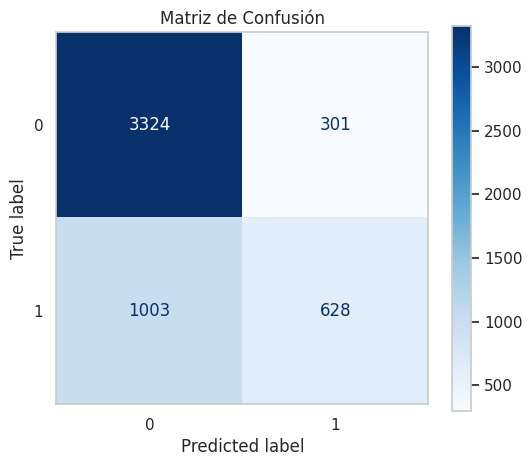

In [90]:
y_pred_c = log_model.predict(X_test_c)

# accuracy
accuracy = accuracy_score(y_test_c, y_pred_c)
print(f"Exactitud (Accuracy) del modelo de Regresión Logística: {accuracy:.4f} ({(accuracy*100):.2f}%)")

# matriz de confusión
cm = confusion_matrix(y_test_c, y_pred_c)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=log_model.classes_)
fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(cmap="Blues", ax=ax)
plt.title("Matriz de Confusión")
plt.grid(False)
plt.show()

d) (0.75 pts) Interpreta qué factores parecen asociarse más a la alta demanda (coeficientes del modelo logístico y/o importancia si usas un árbol; o argumentación basada en tus gráficos del ejercicio 2).


In [93]:

coef_df = pd.DataFrame({
    "Predictor": predictors,
    "Coeficiente": log_model.coef_[0]
}).sort_values(by="Coeficiente", ascending=False)


display(coef_df)


,Predictor,Coeficiente
5,is_weekend,0.675784
4,is_workingday,0.155163
1,temp_c,0.094378
0,hour,0.049890
2,humidity,-0.014387
3,wind_kmh,-0.029520


La temp_c es la varaible factor positivo más fuerte. Un posible aumento en la
variable temp está directamente relacionado con una probabilidad mayor de alcanzar una alta demanda

La humidity tiene un coeficiente negativo muy marcado, indicando que a mayor humedad en el ambiente como comentabamos en ejercicios anteriores, mayor probabilidad de mal tiempo, por lo que por sentido común la probabilidad de que exista alta demanda disminuye.

La hour, podemos ver también tiene un coeficiente positivo significativo, lo cual tiene sentido con las horas pico de uso del transporte de micromobility


## Ejercicio 5 — Conclusión (1 punto)

En un máximo de **300 palabras**, resume:

* Qué factores (hora, clima, tipo de día, etc.) parecen mover más la demanda de micromovilidad.  
* Qué modelo predictivo te ha funcionado mejor y por qué.  
* Qué mejorarías con más tiempo o datos (más ciudades, eventos, precio dinámico, etc.).


Al finalizar:

**[Subé el enlace aquí](https://forms.cloud.microsoft/e/vSwHis0f1B)**



1) Los factores que parecer mover más la demanda son la hour y el tipo de día si es laborable o festivo. Ya que hemos observado que hay picos de movilidad tanto en las horas de entrada/salida del trabajo como en las horas centrales del dia en festivos

2) El modelo que mejor ha funcionado ha sido el Random Forest, ya que se adpata mejor a relaciones no lineales, ya que su coef R cuadrado supera al de la Regresion Linel, además de tener un error significativamente menor. Por lo que concluimos que el Random Forest aproxima mucho mejor que la Lineal Regresion

3) Para mejorar podríanmos incluir datos de la localizacion de la ciudad o varias ciudades de una misma región para ver como varían o como se prevee que vayan a variar sus condiciones meteorológicas. También añadiria información sobre eventos de la propia ciudad que puedan alterar la demanda del servicio o las temporadas de de turismo altas como verano o navidades. Podríamos probar también otros modelos de machine learning para ver si se ajustan mejor que los únicos dos que hemos probado en este inter.